# Phase 2A · 02 · Leave-one-study-out (LOSO)

**Goal:** test the paper's random forest on studies it has never seen, one study at a time, and compare each result with the paper's Table S5.

1. What leave-one-study-out tests.
2. Train on 26 studies, normalize with their numbers, test on the 27th.
3. Compare the 27 AUCs with Table S5.
4. Cross-validation inside each single study, also compared with Table S5.

## Setup

Inputs: the raw shares of the 347 genera and the labels from notebook 1/03, and Table S5 from the paper's supplement (`papers/spreadsheets/mmc5.xlsx`). Outputs go to `results/figures/phase_2/phase_2a/02_loso_random_forest/` and `results/tables/phase_2/phase_2a/02_loso_random_forest/`.

The normalization functions are copied from notebook 1/03 and the forest settings from notebook 2A/01, so this notebook runs on its own.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold

SEED = 2000


def find_project_root() -> Path:
    """Walk up from the current folder to the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("No requirements.txt above this folder.")
        folder = folder.parent
    return folder


PROJECT_ROOT = find_project_root()
INPUTS = PROJECT_ROOT / "data" / "processed" / "phase_1" / "03_preprocessing"
SHEETS = PROJECT_ROOT / "papers" / "spreadsheets"
FIGURES = PROJECT_ROOT / "results" / "figures" / "phase_2" / "phase_2a" / "02_loso_random_forest"
TABLES = PROJECT_ROOT / "results" / "tables" / "phase_2" / "phase_2a" / "02_loso_random_forest"
for folder in (FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))


PSEUDOCOUNT = 1e-5


def fit_log_std(relab: pd.DataFrame) -> tuple[pd.Series, pd.Series]:
    """Learn each genus's mean and spread (standard deviation + its 10th percentile) on the log scale."""
    logged = np.log10(relab + PSEUDOCOUNT)
    sd = logged.std(ddof=1)
    return logged.mean(), sd + np.quantile(sd, 0.1)


def apply_log_std(relab: pd.DataFrame, mean: pd.Series, spread: pd.Series) -> pd.DataFrame:
    """Log-transform and standardize with already learned numbers."""
    return (np.log10(relab + PSEUDOCOUNT) - mean) / spread


def make_forest(n_jobs: int = -1) -> RandomForestClassifier:
    return RandomForestClassifier(n_estimators=200, max_features="sqrt", n_jobs=n_jobs, random_state=SEED)

In [2]:
relab = pd.read_csv(INPUTS / "relab_347.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
labels = pd.read_csv(INPUTS / "labels.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
assert relab.index.equals(labels.index), "abundances and labels must be in the same row order"

paper_s5 = pd.read_excel(SHEETS / "mmc5.xlsx", skiprows=1)
paper_loso = paper_s5[paper_s5["ML_approach"] == "LOSO"].set_index("Test")["AUC"]
paper_scv = paper_s5[paper_s5["ML_approach"] == "SCV"].set_index("Test")["AUC"]
studies = sorted(labels["Cohort"].unique())
print(f"{relab.shape[0]:,} samples, {relab.shape[1]} genera, {len(studies)} studies")
print(f"Table S5 has {len(paper_loso)} LOSO and {len(paper_scv)} within-study CV results")

5,966 samples, 347 genera, 27 studies
Table S5 has 26 LOSO and 27 within-study CV results


## 1. What leave-one-study-out tests

Notebook 01 asked: *across all studies, how well does the model separate cancer from controls?* LOSO asks a harder and more practical question: *if a new hospital sends us its samples, how well does a model trained on everyone else work there?*

The paper's Methods: *"we trained classifiers on all CRC/control samples of all dataset except one and evaluated classifier performance on the held-out dataset (repeating this process for each dataset)"*. So for each of the 27 studies:
1. Put that study aside. It is the **held-out** study.
2. Fit the normalization on the other 26 studies and train one forest on them.
3. Normalize the held-out study with the training numbers (frozen), predict it, and compute its AUC.

In [3]:
def loso_predict(held_out: str) -> np.ndarray:
    """Train on every study except `held_out` and return CRC probabilities for the held-out study's samples."""
    is_held_out = (labels["Cohort"] == held_out).to_numpy()
    train, test = relab[~is_held_out], relab[is_held_out]
    mean, spread = fit_log_std(train)
    forest = make_forest()
    forest.fit(apply_log_std(train, mean, spread), labels.loc[~is_held_out, "label"])
    return forest.predict_proba(apply_log_std(test, mean, spread))[:, 1]


start = time.perf_counter()
rows = []
for study in studies:
    is_held_out = labels["Cohort"] == study
    rows.append({
        "study": study,
        "assay": labels.loc[is_held_out, "Assay"].iloc[0],
        "n_train": int((~is_held_out).sum()),
        "n_test": int(is_held_out.sum()),
        "our_auc": roc_auc_score(labels.loc[is_held_out, "label"], loso_predict(study)),
    })
print(f"Trained {len(studies)} forests in {time.perf_counter() - start:.0f} s")

loso = pd.DataFrame(rows).set_index("study")
loso["paper_auc"] = paper_loso.reindex(loso.index)
loso["difference"] = loso["our_auc"] - loso["paper_auc"]
loso.round(4).to_csv(TABLES / "loso_auc.csv")
loso.round(3).sort_values("paper_auc")

Trained 27 forests in 35 s


,assay,n_train,n_test,our_auc,paper_auc,difference
study,,,,,,
HanniganGD_2018,WGS,5934,32,0.709,0.707,0.002
YachidaS_2019,WGS,5468,498,0.734,0.745,-0.011
BaxterNT_2016,16S,5726,240,0.759,0.778,-0.019
VogtmannE_2016,WGS,5862,104,0.769,0.783,-0.013
YoungC2_2021,16S,5360,606,0.606,0.794,-0.188
YangY_2021a,16S,5264,702,0.824,0.813,0.011
OkumuraS_2021,16S,4940,1026,0.811,0.816,-0.004
ThomasAM_2019_1,WGS,5918,48,0.833,0.819,0.014
YangY_2021c,WGS,5768,198,0.813,0.819,-0.006


## 2. Compare with the paper

`DuX_2022` has no LOSO value in Table S5, although the text says "across the 27 studies". Its other Table S5 rows are present, so the LOSO row seems to be missing from the supplement. The comparison uses the other 26 studies.

In [4]:
compared = loso.dropna(subset=["paper_auc"])
mean_absolute_difference = compared["difference"].abs().mean()
correlation = compared["our_auc"].corr(compared["paper_auc"])
far_off = compared[compared["difference"].abs() > 0.05]

print(f"Mean absolute difference over {len(compared)} studies: {mean_absolute_difference:.3f}")
print(f"Correlation between our and the paper's AUCs: {correlation:.2f}")
print(f"Our mean LOSO AUC {compared['our_auc'].mean():.3f}, paper's {compared['paper_auc'].mean():.3f}")
print(f"Studies off by more than 0.05: {len(far_off)}")
far_off.round(3)

Mean absolute difference over 26 studies: 0.021
Correlation between our and the paper's AUCs: 0.86
Our mean LOSO AUC 0.836, paper's 0.851
Studies off by more than 0.05: 2


,assay,n_train,n_test,our_auc,paper_auc,difference
study,,,,,,
YoungC1_2021,16S,5886,80,0.797,0.861,-0.064
YoungC2_2021,16S,5360,606,0.606,0.794,-0.188


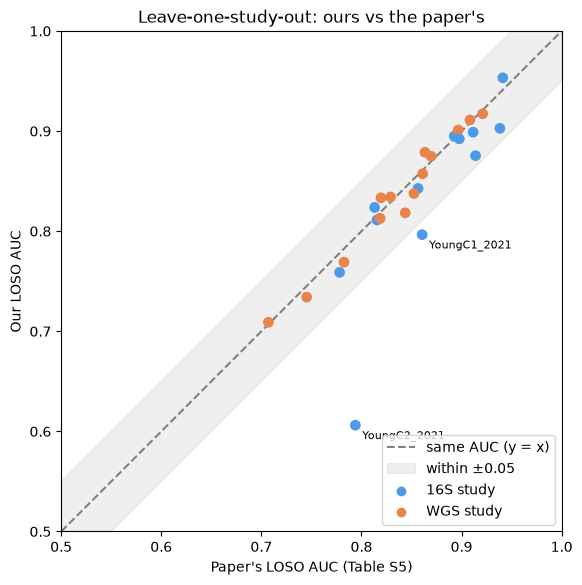

**Figure 1.** Each dot is one held-out study (26 with a value in Table S5). Our AUCs differ from the paper's by 0.021 on average (correlation 0.86). 24 studies fall inside the ±0.05 band and 2 outside. Our mean is 0.836, the paper's 0.851. The paper reports a LOSO range of 0.70 to 0.94, ours is 0.61 (YoungC2_2021) to 0.95 (DengX_2018).

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
colors = compared["assay"].map({"16S": "#4C9BE8", "WGS": "#E8834C"})
ax.scatter(compared["paper_auc"], compared["our_auc"], c=colors, s=45, zorder=3)
ax.plot([0.5, 1], [0.5, 1], color="grey", linestyle="--", label="same AUC (y = x)")
ax.fill_between([0.5, 1], [0.45, 0.95], [0.55, 1.05], color="grey", alpha=0.12, label="within ±0.05")
for study, row in far_off.iterrows():
    ax.annotate(study, (row["paper_auc"], row["our_auc"]), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax.scatter([], [], color="#4C9BE8", label="16S study")
ax.scatter([], [], color="#E8834C", label="WGS study")
ax.set_xlim(0.5, 1)
ax.set_ylim(0.5, 1)
ax.set_aspect("equal")
ax.set_xlabel("Paper's LOSO AUC (Table S5)")
ax.set_ylabel("Our LOSO AUC")
ax.set_title("Leave-one-study-out: ours vs the paper's")
ax.legend(loc="lower right")

show_figure(
    fig,
    "loso_vs_paper",
    f"Each dot is one held-out study ({len(compared)} with a value in Table S5). Our AUCs differ from the paper's by "
    f"{mean_absolute_difference:.3f} on average (correlation {correlation:.2f}). {len(compared) - len(far_off)} studies fall "
    f"inside the ±0.05 band and {len(far_off)} outside. Our mean is {compared['our_auc'].mean():.3f}, the paper's "
    f"{compared['paper_auc'].mean():.3f}. The paper reports a LOSO range of 0.70 to 0.94, ours is "
    f"{loso['our_auc'].min():.2f} ({loso['our_auc'].idxmin()}) to {loso['our_auc'].max():.2f} ({loso['our_auc'].idxmax()}).",
)

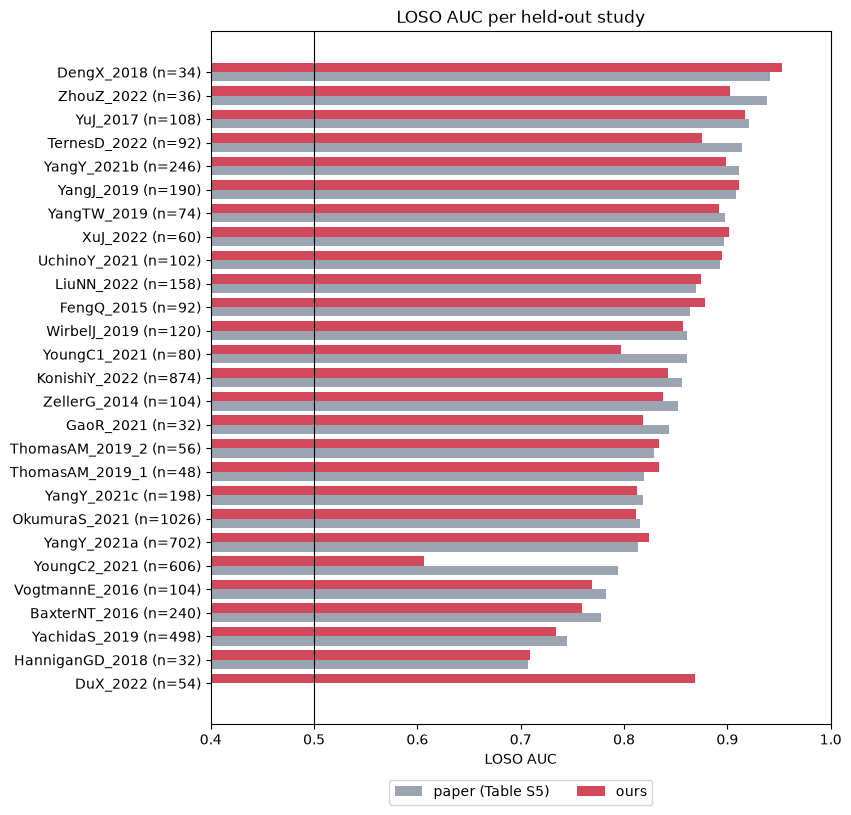

**Figure 2.** Studies are sorted by the paper's AUC. DuX_2022 (bottom) has no paper value. Our hardest study is YoungC2_2021 (AUC 0.61, 606 test samples). Small studies swing more: with 32 test samples (16 CRC, 16 controls), one pair ranked the other way already moves the AUC by 1/256 ≈ 0.004.

In [6]:
ordered = loso.sort_values("paper_auc", na_position="first")
positions = np.arange(len(ordered))

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(positions - 0.2, ordered["paper_auc"].fillna(0), height=0.4, color="#9AA5B1", label="paper (Table S5)")
ax.barh(positions + 0.2, ordered["our_auc"], height=0.4, color="#D1495B", label="ours")
ax.set_yticks(positions, [f"{study} (n={row.n_test})" for study, row in ordered.iterrows()])
ax.axvline(0.5, color="black", linewidth=0.8)
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("LOSO AUC")
ax.set_title("LOSO AUC per held-out study")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2)

hardest = loso["our_auc"].idxmin()
show_figure(
    fig,
    "loso_per_study",
    f"Studies are sorted by the paper's AUC. DuX_2022 (bottom) has no paper value. Our hardest study is {hardest} "
    f"(AUC {loso.loc[hardest, 'our_auc']:.2f}, {loso.loc[hardest, 'n_test']} test samples). Small studies swing more: "
    f"with 32 test samples (16 CRC, 16 controls), one pair ranked the other way already moves the AUC by 1/256 ≈ 0.004.",
)

### The studies outside ±0.05

Two studies, both from the same publication (Young et al. 2021), are more than 0.05 below the paper:

- **YoungC1_2021** has 80 test samples and is 0.06 below (0.797 against 0.861). Inside the study itself our within-study AUC matches the paper (section 3), so the gap only shows when the model comes from the other studies.
- **YoungC2_2021** has 606 test samples and is 0.19 below (0.606 against 0.794). It is also 0.10 below in within-study CV (0.793 against 0.896). The next cell shows that its profiles look unlike the rest: far fewer of its genera are zero.

The data is the published Zenodo file and the method follows the paper's text, so we report both gaps as unexplained.

In [7]:
young = (labels["Cohort"] == "YoungC2_2021").to_numpy()
zero_share_young = (relab[young] == 0).to_numpy().mean()
zero_share_rest = (relab[~young] == 0).to_numpy().mean()
print(f"Share of zeros in the 347 genera: YoungC2_2021 {zero_share_young:.0%}, all other studies {zero_share_rest:.0%}")

Share of zeros in the 347 genera: YoungC2_2021 39%, all other studies 66%


## 3. Cross-validation inside each single study

Table S5 also reports how well a model does **within** one study (`SCV`): train and test on samples from the same study. There is no study effect to exploit here, but also far fewer samples to learn from. The paper shows both in Figure 3C.

For each study we run 10 times repeated, stratified 10-fold cross-validation and take the median over the repeats, as in notebook 01. Normalization is again fitted on each training fold only. In a small study, some genera are zero in every training sample of a fold. Such a constant column can't be split on and has no spread to divide by, so it is left out of that fold.

That is 27 × 100 = 2,700 small forests. One after another they would take over ten minutes, mostly overhead, so the 100 forests of a study are trained at the same time, one per CPU core, with `joblib.Parallel`. The results are the same, it just runs faster.

In [8]:
def within_study_auc(relab: pd.DataFrame, y: np.ndarray) -> float:
    """10x10 stratified cross-validation inside one study; AUC of the median prediction over repeats."""
    splits = list(RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEED).split(relab, y))

    def fit_and_predict(train_idx: np.ndarray, test_idx: np.ndarray) -> np.ndarray:
        train = relab.iloc[train_idx]
        varying = train.columns[train.nunique() > 1]
        mean, spread = fit_log_std(train[varying])
        forest = make_forest(n_jobs=1)
        forest.fit(apply_log_std(train[varying], mean, spread), y[train_idx])
        return forest.predict_proba(apply_log_std(relab.iloc[test_idx][varying], mean, spread))[:, 1]

    fold_predictions = Parallel(n_jobs=-1)(delayed(fit_and_predict)(train_idx, test_idx) for train_idx, test_idx in splits)

    predictions = np.full((len(y), 10), np.nan)
    for split_number, ((_, test_idx), fold_prediction) in enumerate(zip(splits, fold_predictions)):
        predictions[test_idx, split_number // 10] = fold_prediction
    assert not np.isnan(predictions).any()
    return roc_auc_score(y, np.median(predictions, axis=1))


start = time.perf_counter()
scv_rows = []
for study in studies:
    in_study = (labels["Cohort"] == study).to_numpy()
    scv_rows.append({
        "study": study,
        "n_samples": int(in_study.sum()),
        "our_auc": within_study_auc(relab[in_study], labels.loc[in_study, "label"].to_numpy()),
    })
print(f"Trained {len(studies) * 100:,} forests in {time.perf_counter() - start:.0f} s")

scv = pd.DataFrame(scv_rows).set_index("study")
scv["paper_auc"] = paper_scv.reindex(scv.index)
scv["difference"] = scv["our_auc"] - scv["paper_auc"]
scv.round(4).to_csv(TABLES / "scv_auc.csv")
scv_mad = scv["difference"].abs().mean()
print(f"Within-study CV: mean absolute difference {scv_mad:.3f} over {scv['paper_auc'].notna().sum()} studies, "
      f"correlation {scv['our_auc'].corr(scv['paper_auc']):.2f}")

Trained 2,700 forests in 231 s
Within-study CV: mean absolute difference 0.032 over 27 studies, correlation 0.90


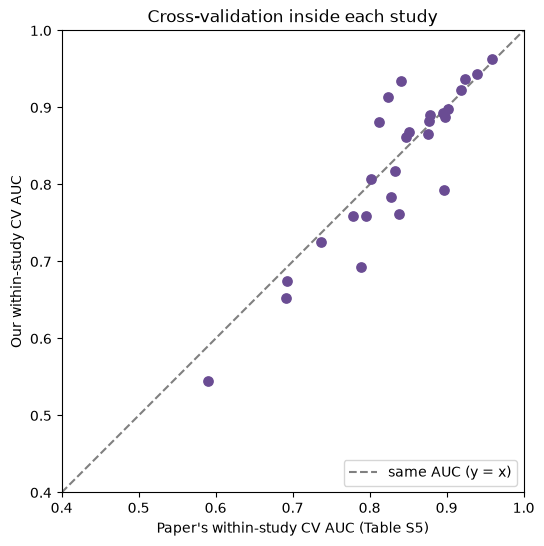

**Figure 3.** Each dot is one study. Our within-study AUCs differ from the paper's by 0.032 on average (correlation 0.90). The mean within-study AUC is 0.826 (paper 0.834), against our mean LOSO AUC of 0.838 over all 27 studies.

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(scv["paper_auc"], scv["our_auc"], color="#6A4C93", s=45, zorder=3)
ax.plot([0.4, 1], [0.4, 1], color="grey", linestyle="--", label="same AUC (y = x)")
ax.set_xlim(0.4, 1)
ax.set_ylim(0.4, 1)
ax.set_aspect("equal")
ax.set_xlabel("Paper's within-study CV AUC (Table S5)")
ax.set_ylabel("Our within-study CV AUC")
ax.set_title("Cross-validation inside each study")
ax.legend(loc="lower right")

show_figure(
    fig,
    "scv_vs_paper",
    f"Each dot is one study. Our within-study AUCs differ from the paper's by {scv_mad:.3f} on average "
    f"(correlation {scv['our_auc'].corr(scv['paper_auc']):.2f}). The mean within-study AUC is {scv['our_auc'].mean():.3f} "
    f"(paper {scv['paper_auc'].mean():.3f}), against our mean LOSO AUC of {loso['our_auc'].mean():.3f} over all 27 studies.",
)

## 4. Checks

In [10]:
assert len(paper_loso) == 26 and "DuX_2022" not in paper_loso.index
assert len(loso) == 27 and loso["our_auc"].between(0.5, 1.0).all()
assert (loso["n_train"] + loso["n_test"] == len(labels)).all(), "each LOSO model trains on all other studies"
assert len(scv) == 27 and scv["our_auc"].notna().all()
print("All checks passed.")

All checks passed.


## What we learned

- Leave-one-study-out tests the real use case: a model trained on 26 studies, applied to a study it has never seen. Normalization is learned on the 26 training studies and applied frozen to the held-out one, as the paper describes.
- Our 26 LOSO AUCs differ from Table S5 by **0.021 on average** (correlation 0.86), and 24 of 26 studies are within ±0.05. Our mean is 0.836, the paper's 0.851.
- The two studies outside ±0.05 are YoungC1_2021 (0.80 against 0.86) and **YoungC2_2021 (0.61 against 0.79)**. YoungC2_2021 has far fewer zeros than the other studies (39% against 66%) and is also low inside its own study. Both gaps are reported as unexplained.
- DuX_2022 has no LOSO row in Table S5. Our value, 0.868, is reported without a comparison.
- Within single studies, cross-validation reaches a mean AUC of 0.826 (paper 0.834, mean absolute difference 0.032, correlation 0.90). Our mean LOSO AUC over all 27 studies (0.838) is slightly higher: a model trained on 26 other studies does a little better than one trained inside the study, because pooling gives far more training data.